# Base rate, logistic and regularized tree

Fixed model settings plus dedicated calibration and validation prevent test-driven selection. Selection minimizes validation Brier then log loss. Comparison classification cutoffs differ from the policy threshold.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT))
T=ROOT/'artifacts/tables'; F=ROOT/'artifacts/figures'
summary=json.loads((T/'run_summary.json').read_text())


,candidate,roc_auc,average_precision,precision,recall,f1,ks,brier,log_loss,tn,fp,fn,tp,threshold
0,xgboost:sigmoid,0.778209,0.536921,0.640162,0.349522,0.452166,0.420277,0.140055,0.440492,4389,267,884,475,0.5
1,xgboost:raw,0.778209,0.536921,0.631788,0.350993,0.451277,0.420277,0.140300,0.441229,4378,278,882,477,0.5
2,xgboost:isotonic,0.777717,0.517716,0.626521,0.378955,0.472260,0.413691,0.140711,0.442651,4349,307,844,515,0.5
3,logistic:isotonic,0.757370,0.491594,0.622829,0.369389,0.463741,0.401778,0.143322,0.462858,4352,304,857,502,0.5
4,logistic:sigmoid,0.758922,0.508039,0.653903,0.326711,0.435721,0.404531,0.143335,0.452379,4421,235,915,444,0.5
5,logistic:raw,0.758922,0.508039,0.644444,0.341428,0.446368,0.404531,0.143729,0.454057,4400,256,895,464,0.5
6,base_rate:raw,0.500000,0.225935,0.000000,0.000000,0.000000,0.000000,0.174909,0.534376,4656,0,1359,0,0.5


,candidate,roc_auc,average_precision,precision,recall,f1,ks,brier,log_loss,tn,fp,fn,tp,threshold
0,base_rate:raw,0.500000,0.218636,0.000000,0.000000,0.000000,0.000000,0.170842,0.525199,4696,0,1314,0,0.5
1,logistic:raw,0.763361,0.537274,0.686944,0.352359,0.465795,0.418624,0.135454,0.435540,4485,211,851,463,0.5
2,logistic:sigmoid,0.763361,0.537274,0.698891,0.335616,0.453470,0.418624,0.135627,0.435385,4506,190,873,441,0.5
3,logistic:isotonic,0.761410,0.512824,0.665813,0.395738,0.496420,0.400243,0.135459,0.434002,4435,261,794,520,0.5
4,xgboost:raw,0.780840,0.559073,0.693277,0.376712,0.488166,0.430193,0.132463,0.424171,4477,219,819,495,0.5
5,xgboost:sigmoid,0.780840,0.559073,0.690647,0.365297,0.477850,0.430193,0.132508,0.424168,4481,215,834,480,0.5
6,xgboost:isotonic,0.779936,0.536479,0.664968,0.397260,0.497380,0.427781,0.132847,0.425970,4433,263,792,522,0.5


Frozen winner: xgboost:sigmoid


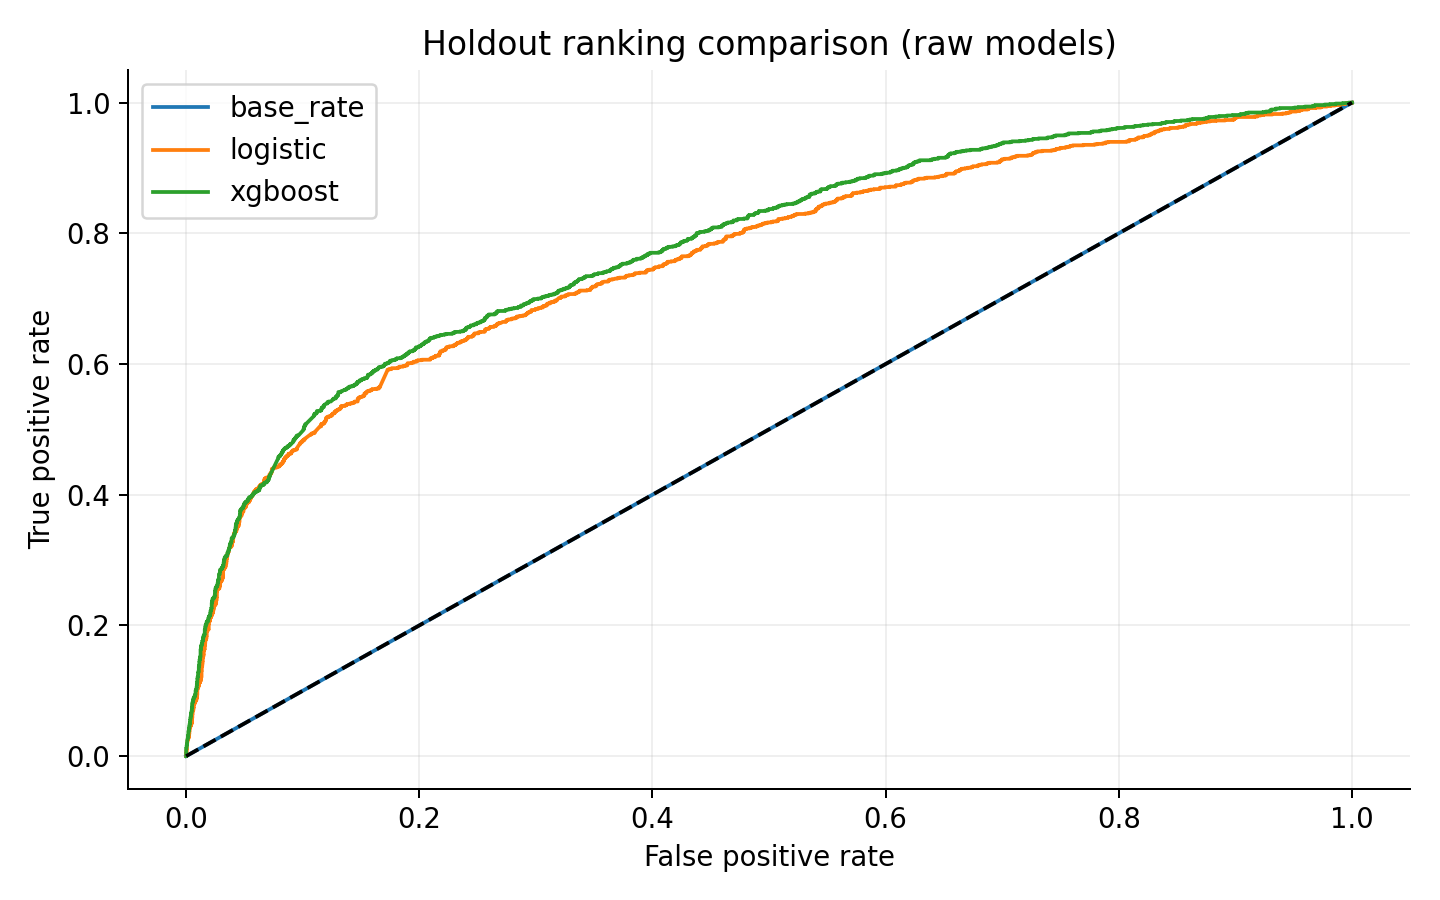

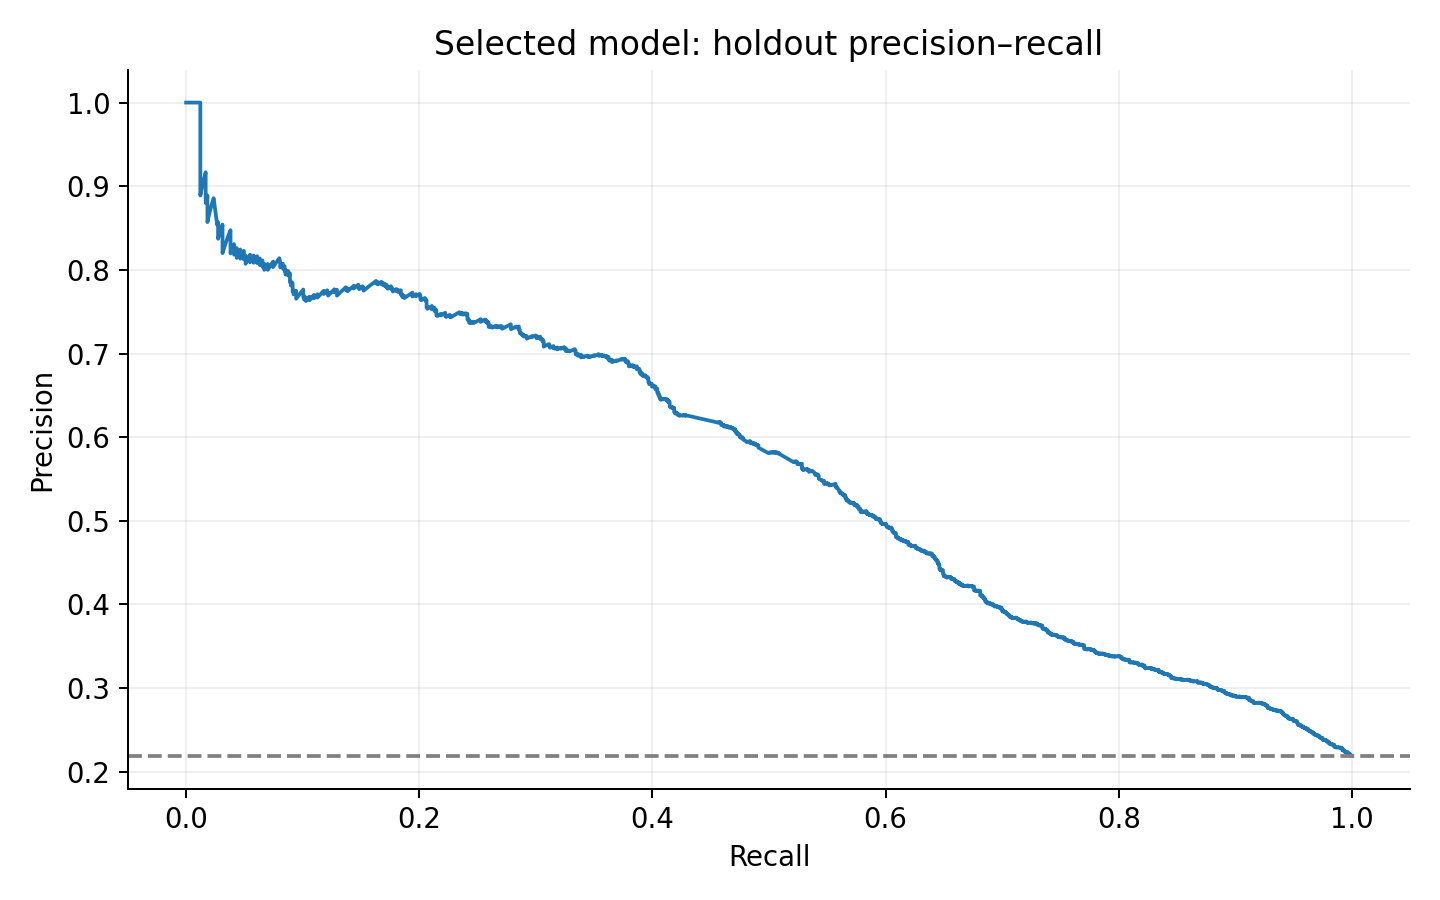

In [2]:
display(pd.read_csv(T/'validation_models.csv'))
display(pd.read_csv(T/'test_models.csv'))
print('Frozen winner:',summary['selected'])
display(Image(filename=str(F/'roc.png')))
display(Image(filename=str(F/'precision_recall.png')))